# Solutions to notebook 3: Calculus: derivatives, integrals, limits and series

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/03_calculus.ipynb)

Worked solutions to the exercises at the end of [notebook 3](../notebooks/03_calculus.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## Exercise 1

Find the isothermal compressibility $\kappa_T = -\dfrac{1}{V}\left(\dfrac{\partial V}{\partial P}\right)_T$
of a van der Waals gas and check the ideal-gas limit $1/P$.

The equation gives $P(V, T)$, not $V(P, T)$, so use the reciprocal rule
$\left(\partial V/\partial P\right)_T = 1 / \left(\partial P/\partial V\right)_T$.

In [2]:
R, T, V, a, b = sp.symbols("R T V a b", positive=True)
P_vdw = R * T / (V - b) - a / V**2

kappa = sp.simplify(-1 / (V * sp.diff(P_vdw, V)))
kappa

      2        2     
     V ⋅(V - b)      
─────────────────────
     3              2
R⋅T⋅V  - 2⋅a⋅(V - b) 

In [3]:
# verify 1: the ideal-gas limit a = b = 0, where P = RT/V and kappa must equal 1/P
kappa_ideal = sp.simplify(kappa.subs({a: 0, b: 0}))
assert sp.simplify(kappa_ideal - 1 / (R * T / V)) == 0
kappa_ideal

 V 
───
R⋅T

In [4]:
# verify 2: a finite difference for CO2 at 320 K near 50 bar (constants of notebook 2).
# Find V at three nearby pressures from the cubic, as in notebook 2, and form -(1/V) dV/dP directly.
P = sp.symbols("P", positive=True)
co2 = {a: 0.3640, b: 4.267e-5, R: 8.314, T: 320}
cubic = sp.numer(sp.together(P - P_vdw)).subs(co2)

def gas_volume(pressure):
    roots = sp.Poly(cubic.subs(P, pressure), V).nroots()
    return float([root for root in roots if root.is_real][0])      # one real root above T_c

V_low, V_mid, V_high = gas_volume(49.9e5), gas_volume(50e5), gas_volume(50.1e5)

kappa_fd = -(V_high - V_low) / (0.2e5 * V_mid)
kappa_num = float(kappa.subs(co2).subs(V, V_mid))
assert abs(kappa_num / kappa_fd - 1) < 1e-4
print(f"kappa_T = {kappa_num:.3e} 1/Pa (formula), {kappa_fd:.3e} 1/Pa (finite difference), ideal gas {1 / 50e5:.3e} 1/Pa")

kappa_T = 2.684e-07 1/Pa (formula), 2.684e-07 1/Pa (finite difference), ideal gas 2.000e-07 1/Pa


**Answer.** $\kappa_T = \dfrac{V^2\,(V-b)^2}{R\,T\,V^3 - 2a\,(V-b)^2}$.
With $a = b = 0$ this reduces to $V/(RT) = 1/P$, the ideal-gas value. For CO₂ at 320 K and
50 bar the van der Waals value is about $2.7\times10^{-7}$ Pa⁻¹, larger than the ideal-gas
$2.0\times10^{-7}$ Pa⁻¹, because the attraction between molecules makes the gas easier to compress.

## Exercise 2

Repeat 3.3 for a beam simply supported at both ends ($y = 0$ and $y'' = 0$ at $x = 0$ and
$x = L$). The midspan deflection should be $-5wL^4/(384EI)$.

In [5]:
x, L, w, E, I = sp.symbols("x L w E I", positive=True)
C1, C2, C3, C4 = sp.symbols("C1:5")

# four integrations of -w/(EI), each adding a constant (the same general solution as in 3.3)
y = -w * x**4 / (24 * E * I) + C1 * x**3 / 6 + C2 * x**2 / 2 + C3 * x + C4

conditions = [
    y.subs(x, 0),                    # no deflection at the left support
    sp.diff(y, x, 2).subs(x, 0),     # no bending moment at the left support
    y.subs(x, L),                    # no deflection at the right support
    sp.diff(y, x, 2).subs(x, L),     # no bending moment at the right support
]
constants = sp.solve(conditions, [C1, C2, C3, C4])
y_beam = sp.factor(y.subs(constants))
y_beam

              ⎛   2          2⎞ 
-w⋅x⋅(-L + x)⋅⎝- L  - L⋅x + x ⎠ 
────────────────────────────────
             24⋅E⋅I             

In [6]:
y_mid = y_beam.subs(x, L / 2)

# verify: the textbook midspan deflection, the governing equation, the symmetry about midspan
# (zero slope there), and the textbook maximum bending moment M = EI y'' = w L**2 / 8 at midspan
assert sp.simplify(y_mid + 5 * w * L**4 / (384 * E * I)) == 0
assert sp.simplify(E * I * sp.diff(y_beam, x, 4) + w) == 0
assert sp.diff(y_beam, x).subs(x, L / 2) == 0
assert sp.simplify(E * I * sp.diff(y_beam, x, 2).subs(x, L / 2) - w * L**2 / 8) == 0
y_mid

    4   
-5⋅L ⋅w 
────────
384⋅E⋅I 

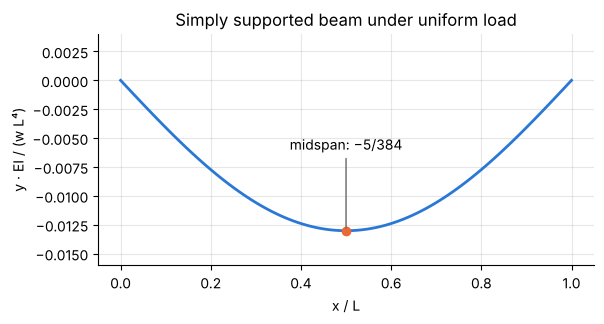

In [7]:
# dimensionless deflection curve: y / (w L^4 / EI) against x / L
xi = sp.symbols("xi")
shape = sp.simplify(y_beam.subs(x, xi * L) / (w * L**4 / (E * I)))
xs = np.linspace(0, 1, 100)

fig, ax = plt.subplots(figsize=(6.4, 3))
ax.plot(xs, sp.lambdify(xi, shape)(xs))
ax.plot(0.5, -5 / 384, "o", color="#eb6834")
ax.set(xlabel="x / L", ylabel="y · EI / (w L⁴)", ylim=(-0.016, 0.004), title="Simply supported beam under uniform load")
ax.annotate("midspan: −5/384", xy=(0.5, -5 / 384), xytext=(0.5, -0.006), ha="center",
            arrowprops={"arrowstyle": "-", "color": "0.4"});

**Answer.** $y(x) = -\dfrac{w\,x\,(L - x)\,(L^2 + Lx - x^2)}{24EI} = -\dfrac{w\,x\,(L^3 - 2Lx^2 + x^3)}{24EI}$,
and the midspan deflection is $y(L/2) = -\dfrac{5wL^4}{384EI}$, as stated. This is about a tenth
of the tip deflection of a cantilever of the same length, $-wL^4/(8EI)$.

## Exercise 3

A closed cylindrical tank of fixed volume $V_0$ is to be made with the least sheet metal.
Show that the optimum has height equal to diameter.

In [8]:
r, h, V0 = sp.symbols("r h V_0", positive=True)

area = 2 * sp.pi * r**2 + 2 * sp.pi * r * h        # two end caps and the side wall
volume = sp.pi * r**2 * h

# use the fixed volume to eliminate h, then minimize the area over r
h_of_r = sp.solve(sp.Eq(volume, V0), h)[0]
area_r = area.subs(h, h_of_r)

r_opt = sp.solve(sp.diff(area_r, r), r)[0]
h_opt = sp.simplify(h_of_r.subs(r, r_opt))
curvature = sp.simplify(sp.diff(area_r, r, 2).subs(r, r_opt))
r_opt, h_opt, curvature

⎛ 2/3 3 ____   2/3 3 ____      ⎞
⎜2   ⋅╲╱ V₀   2   ⋅╲╱ V₀       ⎟
⎜───────────, ───────────, 12⋅π⎟
⎜    3 ___       3 ___         ⎟
⎝  2⋅╲╱ π        ╲╱ π          ⎠

In [9]:
# the result: height / diameter = 1, and the stationary point is a minimum
assert sp.simplify(h_opt / (2 * r_opt)) == 1
assert curvature.is_positive

# verify with a second method, a Lagrange multiplier: grad(area) = lam * grad(volume)
lam = sp.symbols("lambda", positive=True)
lagrange = sp.solve([sp.diff(area - lam * volume, r), sp.diff(area - lam * volume, h)], [h, lam], dict=True)[0]
assert lagrange[h] == 2 * r

# verify with numbers: for a 1 m^3 tank, a 10 % narrower or wider tank needs more metal
area_1 = sp.lambdify(r, area_r.subs(V0, 1))
r_1 = float(r_opt.subs(V0, 1))
assert area_1(r_1) < area_1(0.9 * r_1) and area_1(r_1) < area_1(1.1 * r_1)
print(f"V0 = 1 m³: r = {r_1:.3f} m, h = {float(h_opt.subs(V0, 1)):.3f} m, area = {area_1(r_1):.3f} m²")

V0 = 1 m³: r = 0.542 m, h = 1.084 m, area = 5.536 m²


**Answer.** With $h = V_0/(\pi r^2)$ the area is $A(r) = 2\pi r^2 + 2V_0/r$. Setting
$dA/dr = 0$ gives $r = \left(\dfrac{V_0}{2\pi}\right)^{1/3}$ and
$h = \left(\dfrac{4V_0}{\pi}\right)^{1/3} = 2r$, so the height equals the diameter. The second
derivative is $12\pi > 0$, so this is a minimum. A 1 m³ tank is 1.084 m in both height and
diameter and needs 5.54 m² of sheet.

## Exercise 4

Expand $\dfrac{1}{1-x}$ and $\ln(1+x)$ up to and including the $x^4$ term (`n=5` in
`sp.series`). Which familiar approximations do you recognize?

In [10]:
x = sp.symbols("x")          # no assumption: x may have either sign here

geometric = sp.series(1 / (1 - x), x, 0, 5)       # terms up to x**4
logarithm = sp.series(sp.log(1 + x), x, 0, 5)
geometric, logarithm

⎛                                   2    3    4        ⎞
⎜         2    3    4    ⎛ 5⎞      x    x    x     ⎛ 5⎞⎟
⎜1 + x + x  + x  + x  + O⎝x ⎠, x - ── + ── - ── + O⎝x ⎠⎟
⎝                                  2    3    4         ⎠

In [11]:
# verify: the series known by hand, sum of x**k and sum of (-1)**(k+1) x**k / k
assert geometric.removeO() == sum(x**k for k in range(5))
assert logarithm.removeO() == sum(sp.Rational((-1) ** (k + 1), k) * x**k for k in range(1, 5))

# verify with numbers at x = 0.1: the error is about the size of the first neglected term, x**5
assert abs(geometric.removeO().subs(x, 0.1) - 1 / 0.9) < 2 * 0.1**5
assert abs(logarithm.removeO().subs(x, 0.1) - np.log(1.1)) < 0.1**5 / 5

# error of the first-order approximations at x = 0.1
print(f"1/(1-x) ≈ 1 + x:  {abs(1.1 - 1 / 0.9) / (1 / 0.9):.1%} error")
print(f"ln(1+x) ≈ x:      {abs(0.1 - np.log(1.1)) / np.log(1.1):.1%} error")

1/(1-x) ≈ 1 + x:  1.0% error
ln(1+x) ≈ x:      4.9% error


**Answer.**
$\dfrac{1}{1-x} = 1 + x + x^2 + x^3 + x^4 + O(x^5)$ and
$\ln(1+x) = x - \dfrac{x^2}{2} + \dfrac{x^3}{3} - \dfrac{x^4}{4} + O(x^5)$.

The first is the geometric series; its first two terms are the approximation
$1/(1-x) \approx 1 + x$ used for small corrections. The first term of the second is
$\ln(1+x) \approx x$, the reason a small fractional change and a small change in the
logarithm are the same thing. At $x = 0.1$ these one-term approximations are off by 1 % and 5 %.

## Exercise 5

Compute the second moment of area of a rectangle $b \times h$ about its centroidal axis
with a double integral.

Put the origin at the centroid with $y$ across the height. Then $I = \iint y^2\,dA$ with
$-b/2 \le x \le b/2$ and $-h/2 \le y \le h/2$.

In [12]:
b, h = sp.symbols("b h", positive=True)
xc, yc = sp.symbols("x y", real=True)

I_centroid = sp.integrate(yc**2, (yc, -h / 2, h / 2), (xc, -b / 2, b / 2))
I_centroid

   3
b⋅h 
────
 12 

In [13]:
# verify 1: the textbook formula b h**3 / 12
assert sp.simplify(I_centroid - b * h**3 / 12) == 0

# verify 2: the parallel-axis theorem. About the base, I_base = I_centroid + A (h/2)**2,
# where I_base is integrated directly with y measured from the base.
I_base = sp.integrate(yc**2, (yc, 0, h), (xc, 0, b))
assert sp.simplify(I_base - (I_centroid + b * h * (h / 2) ** 2)) == 0
I_base

   3
b⋅h 
────
 3  

**Answer.** $I = \displaystyle\int_{-b/2}^{b/2}\!\int_{-h/2}^{h/2} y^2\,dy\,dx = \dfrac{b\,h^3}{12}$.
About the base the same integral gives $b h^3/3$, which is $I + A\,(h/2)^2$ as the parallel-axis
theorem requires. The height enters cubed, which is why a beam is much stiffer standing on edge.